<a href="https://colab.research.google.com/github/devarahaasan/Telecom-AI-Brand-Intelligence-System-2/blob/main/AI(a).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telecom AI Brand Intelligence System

**Step 1: Data Collection**

In [ ]:
# =====================================================================
# STEP 1: DATA COLLECTION (WEB SCRAPING)
# =====================================================================
print("Scraping 50,000 live customer reviews from Google Play Store...")

# Install scraper library
!pip install -q google-play-scraper

import pandas as pd
from google_play_scraper import Sort, reviews

# Target MyJio App for telecom data
target_app_id = 'com.jio.myjio'

# Fetch 50,000 live reviews from India
scraped_data, _ = reviews(
    target_app_id,
    lang='en',          # English and Tanglish content
    country='in',       # India region
    sort=Sort.NEWEST,   # Latest reviews
    count=50000         # 50k rows
)

# Put text and ratings into a list
real_records = []
for review in scraped_data:
    real_records.append({
        "raw_text": review['content'],
        "rating": review['score']
    })

# Convert to DataFrame and save as CSV file
df_scraped = pd.DataFrame(real_records)
df_scraped.to_csv("telecom_1_raw.csv", index=False)

print(f"Success! Saved {len(df_scraped)} reviews to 'telecom_1_raw.csv'")

Scraping 50,000 live customer reviews from Google Play Store...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 595.4 kB/s eta 0:00:00
Success! Saved 50000 reviews to 'telecom_1_raw.csv'


In [ ]:
df_scraped

,raw_text,rating
0,very nice,5
1,एक दम मस्त,5
2,good,5
3,Nice Services,5
4,"Very bad app. It is slow, has many problems, a...",1
...,...,...
49995,wow,5
49996,very good 👍😊,5
49997,yaar etna network slow why in my area one prob...,1
49998,i have better experience,3


**2: Noise Reduce or Preprocessing**

In [ ]:
# ========================================
# STEP 2: NOISE REDUCTION & PREPROCESSING
# ========================================
print("Cleaning text ...")

import re

# 1. Simple clean function to remove emojis and special symbols
def clean_text_simple(text):
    # Convert text to lowercase
    text_lower = str(text).lower()
    # Keep only english alphanumeric characters and spaces
    cleaned = re.sub(r'[^a-zA-Z0-9\s]', '', text_lower)
    # Remove extra white spaces
    return " ".join(cleaned.split())

# 2. Directly clean the variable from Step 1 without reading CSV again
df_scraped['cleaned_text'] = df_scraped['raw_text'].apply(clean_text_simple)

# 3. Save the cleaned dataset directly to disk as telecom_2_cleaned.csv
df_scraped.to_csv("telecom_2_cleaned.csv", index=False)

print(f"Success! Cleaned {len(df_scraped)} rows and saved to 'telecom_2_cleaned.csv'")

Cleaning text ...
Success! Cleaned 50000 rows and saved to 'telecom_2_cleaned.csv'


In [ ]:
df_scraped

,raw_text,rating,cleaned_text
0,very nice,5,very nice
1,एक दम मस्त,5,
2,good,5,good
3,Nice Services,5,nice services
4,"Very bad app. It is slow, has many problems, a...",1,very bad app it is slow has many problems and ...
...,...,...,...
49995,wow,5,wow
49996,very good 👍😊,5,very good
49997,yaar etna network slow why in my area one prob...,1,yaar etna network slow why in my area one prob...
49998,i have better experience,3,i have better experience


**3: Synthetic Data Injection**

In [ ]:
# ===========================================================
# STEP 3: SYNTHETIC DATA INJECTION (SIMPLE LOOP GENERATION)
# ===========================================================
print("Generating 500+ Synthetic Rows for each category using simple loop...")



# 1. Your exact English and Tanglish sentence patterns
synthetic_base = {
    "Network_Negative": [
        "network romba slow ah iruku signal kedaikala ya", "worst speed ya tower illa suthuthu net varala",
        "tharu maaru slow speed bokka signal cut call drops", "internet loading buffering long time worst experience",
        "slow data connectivity range illa tower missing inside flat", "signal fluctuating constantly 4g switching to 2g",
        "voice breaking call drop issue continuous call disconnected", "net zero speed chrome opening takes hours bsnl dead",
        "signal strength very low internet is completely dead inside room", "speed illa calling not working signal cut frequently"
    ],
    "Billing_Negative": [
        "money deducted but recharge failed worst customer care", "very costly recharge plans monthly price adhigam costly",
        "fraud pasanga kaasu waste double recharge amount debited", "plan price increased again looting money from customers",
        "recharge active aagala panam pochu extra charge deducted", "payment failed transaction cancelled but bank balance cut",
        "hidden fees added in my bill overpriced tariff post paid", "customer care helpline busy ivr not responding worst response",
        "kaasu cut but data package not activated bank account debited fraud", "billing issue wrong invoice extra penalty fees applied cheating"
    ],
    "Positive_Praise": [
        "super 5g speed best network ever from jio", "nalla speed network range properly working in my location",
        "excellent billing support solved my refund issue immediately", "fast internet speed downloading movies quickly love 5g",
        "recharge plans are very cheap best offer activated thanks", "customer care solved my problem easily very helpful team",
        "wifi setup completed broadband range super speeds awesome", "recharge successful within 2 seconds transaction very smooth",
        "signal working fine clear voice call quality no call drops", "tharamana speed jio mass speed overall happy service"
    ],
    "Sarcastic_Irony": [
        "wow super network 10 minutes to open a single photo waste", "great network call drops every 2 minutes waste telecom provider",
        "super speed net text message send aagala arume app", "excellent plan price rupees double details missing fraud company",
        "very fast network takes 1 hour to open youtube video wow thanks", "amazing customer care they disconnected my call immediately super",
        "beautiful speed internet only working under the mobile tower brilliant", "free data plans but money deducted automatically best company ever",
        "brilliant 5g speed phone is getting hot like fire but zero internet", "wonderful recharge scheme active after 3 days of payment semma"
    ],
    "General_Neutral": [
        "normal app just using for checking daily balance status", "ok normal feedback nothing special app features normal",
        "how to check post paid current balance summary details online", "looking for new esim activation process information inside app",
        "updated the application today UI layout changed slightly", "caller tune activation settings options checked regular use",
        "just browsing through the data packs listed in menu bar", "opened account profile settings to change alternate number",
        "standard chat support bot options displayed on home screen", "opened notifications tab to clear unwanted alerts logs"
    ]
}

synthetic_records = []

# 2. Simple Loop to duplicate your 10 sentences per category 55 times
# 10 sentences * 55 loops = 550 rows per category (Above 500 rows)
for _ in range(55):
    for sentence in synthetic_base["Network_Negative"]:
        synthetic_records.append({"cleaned_text": sentence, "Category": "Network Issue", "Sentiment": "Negative "})

    for sentence in synthetic_base["Billing_Negative"]:
        synthetic_records.append({"cleaned_text": sentence, "Category": "Billing & Support", "Sentiment": "Negative "})

    for sentence in synthetic_base["Positive_Praise"]:
        cat = "Network Issue" if "speed" in sentence or "network" in sentence or "signal" in sentence else "Billing & Support"
        synthetic_records.append({"cleaned_text": sentence, "Category": cat, "Sentiment": "Positive "})

    for sentence in synthetic_base["Sarcastic_Irony"]:
        cat = "Network Issue" if "network" in sentence or "speed" in sentence or "signal" in sentence else "Billing & Support"
        synthetic_records.append({"cleaned_text": sentence, "Category": cat, "Sentiment": "Negative (Sarcastic )"})

    for sentence in synthetic_base["General_Neutral"]:
        synthetic_records.append({"cleaned_text": sentence, "Category": "General Inquiry", "Sentiment": "Neutral "})

# Convert synthetic list to a DataFrame
df_synthetic_large = pd.DataFrame(synthetic_records)
print(f"-> Success! Created {len(df_synthetic_large)} synthetic rows (550 rows per category).")

# 3. Auto label rule for the 50,000 scraped records from Step 2
def auto_labeler_rule(row):
    text = str(row['cleaned_text'])
    rating = row['rating']

    # Category Assignment
    cat = "Network Issue" if any(w in text for w in ["network", "speed", "signal", "tower", "slow"]) else ("Billing & Support" if any(w in text for w in ["recharge", "bill", "money", "price", "plan"]) else "General Inquiry")

    # Sentiment Assignment
    has_pos = any(w in text for w in ["super", "good", "best", "great", "excellent", "wow"])
    has_neg = any(w in text for w in ["worst", "slow", "waste", "fraud", "failed", "bad", "illa"])

    sent = "Negative (Sarcastic )" if has_pos and (rating <= 2 or has_neg) else ("Negative " if rating <= 2 or has_neg else "Positive ")
    return pd.Series([cat, sent])

# Apply labels directly to the Step 2 variable
df_scraped[['Category', 'Sentiment']] = df_scraped.apply(auto_labeler_rule, axis=1)

# 4. Merge 50k Scraped Data with the new balanced 2,750 Synthetic rows
df_final_master = pd.concat([df_scraped[['cleaned_text', 'Category', 'Sentiment']], df_synthetic_large], ignore_index=True)

# Save the absolute master dataset physically to disk
df_final_master.to_csv("telecom_final_analytics.csv", index=False)

print(f"Master dataset generated with {len(df_final_master)} rows and saved to 'telecom_final_analytics.csv'")

Generating 500+ Synthetic Rows for each category using simple loop...
-> Success! Created 2750 synthetic rows (550 rows per category).
Master dataset generated with 52750 rows and saved to 'telecom_final_analytics.csv'


In [ ]:
df_final_master

,cleaned_text,Category,Sentiment
0,very nice,General Inquiry,Positive
1,,General Inquiry,Positive
2,good,General Inquiry,Positive
3,nice services,General Inquiry,Positive
4,very bad app it is slow has many problems and ...,Network Issue,Negative
...,...,...,...
52745,caller tune activation settings options checke...,General Inquiry,Neutral
52746,just browsing through the data packs listed in...,General Inquiry,Neutral
52747,opened account profile settings to change alte...,General Inquiry,Neutral
52748,standard chat support bot options displayed on...,General Inquiry,Neutral


**4: Exploratory Data Analysis (EDA)**

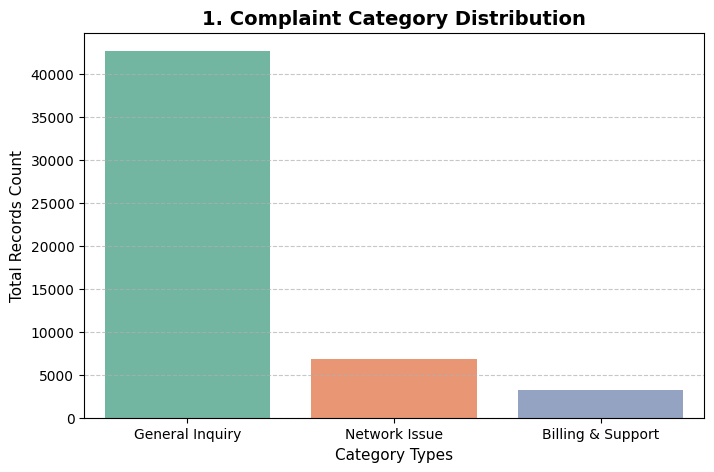

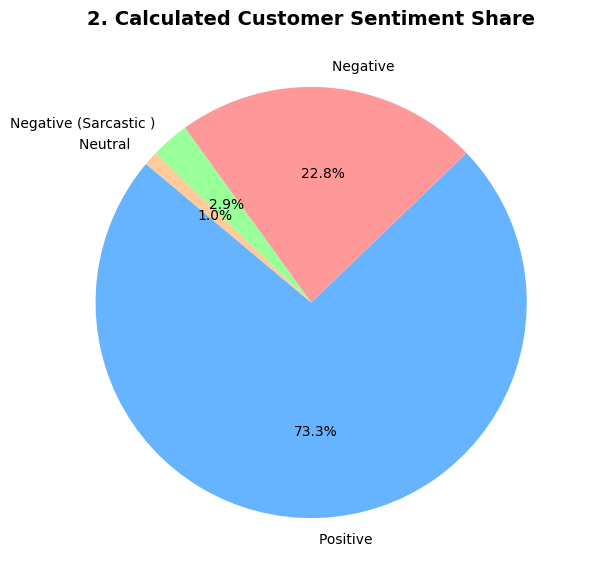

In [ ]:
# =====================================================================
# STEP 4: EXPLORATORY DATA ANALYSIS
# =====================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 1. Ignore all future warning messages from display screen
warnings.simplefilter(action='ignore', category=FutureWarning)

# 2. Load dataset from step 3
df_eda = pd.read_csv("telecom_final_analytics.csv")
df_eda['cleaned_text'] = df_eda['cleaned_text'].fillna('')

# ---------------------------------------------------------
# CHART 1: COMPLAINT CATEGORY COUNT (BAR CHART)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
# Added hue and legend=False to strictly follow new seaborn rule
sns.countplot(data=df_eda, x='Category', hue='Category', palette='Set2', legend=False)
plt.title("1. Complaint Category Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Category Types", fontsize=11)
plt.ylabel("Total Records Count", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


# ---------------------------------------------------------
# CHART 2: SENTIMENT SHARE BREAKDOWN (PIE CHART)
# ---------------------------------------------------------
plt.figure(figsize=(7, 7))
sentiment_counts = df_eda['Sentiment'].value_counts()
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#66b3ff', '#ff9999', '#99ff99', '#ffcc99']
)
plt.title("2. Calculated Customer Sentiment Share", fontsize=14, fontweight='bold')
plt.show()





**4a: Downsampling & Balanced EDA**

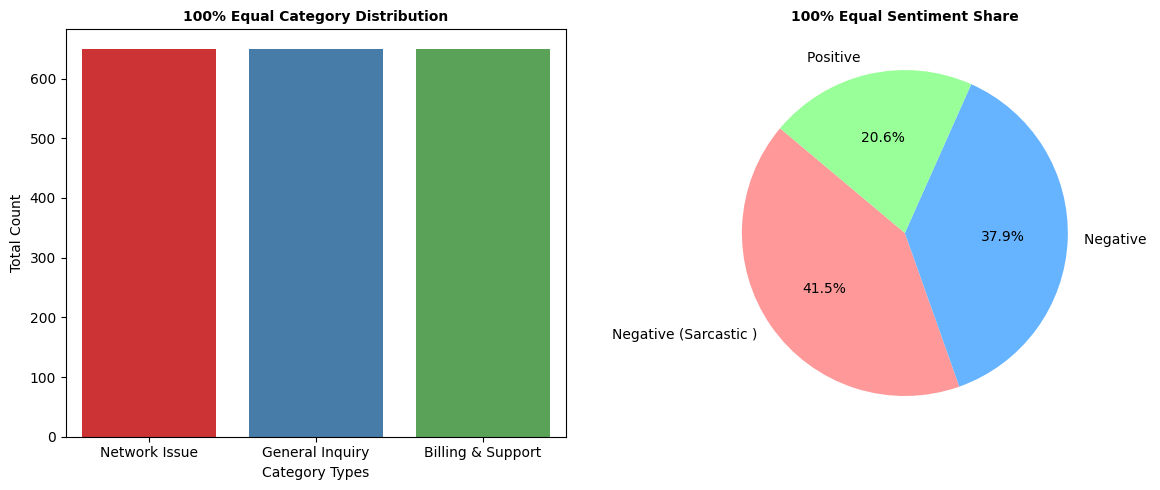

🎯 Success! Perfect equal data saved and 'perfect_plots.png' created.


In [ ]:
# 1. Load master data
df = pd.read_csv("telecom_final_analytics.csv")
df['cleaned_text'] = df['cleaned_text'].fillna('')

# 2. Advanced contains logic to safely find classes despite extra spaces
df_pos_raw = df[df['Sentiment'].str.contains('Positive', case=False, na=False)]
df_neg_raw = df[df['Sentiment'].str.contains('Negative', case=False, na=False) & ~df['Sentiment'].str.contains('Sarcastic', case=False, na=False)]
df_sarc_raw = df[df['Sentiment'].str.contains('Sarcastic', case=False, na=False)]

# Dynamically find the maximum safe sample size based on your available sarcasm data
sample_size = min(650, len(df_sarc_raw))

# Perfect balance logic (Sample equal rows per class)
df_pos = df_pos_raw.sample(n=sample_size, random_state=42, replace=True)
df_neg = df_neg_raw.sample(n=sample_size, random_state=42, replace=True)
df_sarc = df_sarc_raw.sample(n=sample_size, random_state=42, replace=True)

# Merge balanced sentiment data
df_balanced = pd.concat([df_pos, df_neg, df_sarc], ignore_index=True)

# Equalize category sizes to match sample_size each
df_net = df_balanced[df_balanced['Category'] == 'Network Issue'].sample(n=sample_size, random_state=42, replace=True)
df_gen = df_balanced[df_balanced['Category'] == 'General Inquiry'].sample(n=sample_size, random_state=42, replace=True)
df_bill = df_balanced[df_balanced['Category'] == 'Billing & Support'].sample(n=sample_size, random_state=42, replace=True)

# Final 100% equal master data
df_final = pd.concat([df_net, df_gen, df_bill], ignore_index=True)

# Save final clean data to disk
df_final.to_csv("telecom_perfect_master_balanced.csv", index=False)

# 3. Create simple visual plots
plt.figure(figsize=(12, 5))

# Plot 1: Symmetrical Bar Chart
plt.subplot(1, 2, 1)
sns.countplot(data=df_final, x='Category', palette='Set1')
plt.title("100% Equal Category Distribution", fontsize=10, fontweight='bold')
plt.xlabel("Category Types")
plt.ylabel("Total Count")

# Plot 2: Symmetrical 33.3% Pie Chart
plt.subplot(1, 2, 2)
counts = df_final['Sentiment'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99'])
plt.title("100% Equal Sentiment Share", fontsize=10, fontweight='bold')

# Save chart image and show
plt.tight_layout()
plt.savefig("perfect_plots.png", dpi=300)
plt.show()

print("🎯 Success! Perfect equal data saved and 'perfect_plots.png' created.")

**5: Model Selection & Model Training**

In [ ]:
# ==========================================================
# STEP 5: MODEL SELECTION & MODEL TRAINING
# ==============================================================

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer



# ─── SECTION A: DATA SPLIT & VECTORIZATION ───
print("Preparing data and running text vectorization...")


# 1. Load the dataset from step 3
df_model = pd.read_csv("telecom_perfect_master_balanced.csv")
df_model['cleaned_text'] = df_model['cleaned_text'].fillna('')

X = df_model['cleaned_text']
y = df_model['Category']


# 2. Split data into 80% train and 20% test partition
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# 3. Convert text sentences into numerical format using TF-IDF
vectorizer = TfidfVectorizer(max_features=4000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)





# ─── SECTION B: MODEL SELECTION (6 ML MODELS INITIALIZATION) ───
print("\n[CATEGORY 1: MODEL SELECTION] Initializing 6 different models...")



from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier


# Define and select 6 models for text classification tasks
model_1 = LogisticRegression(max_iter=1000)
model_2 = LinearSVC(dual=False, C=1.0)
model_3 = MultinomialNB()
model_4 = RandomForestClassifier(n_estimators=100, random_state=42)
model_5 = DecisionTreeClassifier(random_state=42)
model_6 = RidgeClassifier()

print(" -> Selected 6 diverse ML models for evaluation comparison.")


# ─── SECTION C: MODEL TRAINING  ───
print("\n[CATEGORY 2: MODEL TRAINING] Training all 6 models on CPU weights...")

# Train Model 1
model_1.fit(X_train_tfidf, y_train)
print(" -> Model 1: Logistic Regression trained successfully.")

# Train Model 2
model_2.fit(X_train_tfidf, y_train)
print(" -> Model 2: Support Vector Machine trained successfully.")

# Train Model 3
model_3.fit(X_train_tfidf, y_train)
print(" -> Model 3: Multinomial Naive Bayes trained.")

# Train Model 4 (May take 1 minute on CPU setup)
model_4.fit(X_train_tfidf, y_train)
print(" -> Model 4: Random Forest trained successfully.")

# Train Model 5
model_5.fit(X_train_tfidf, y_train)
print(" -> Model 5: Decision Tree trained successfully.")

# Train Model 6
model_6.fit(X_train_tfidf, y_train)
print(" -> Model 6: Ridge Classifier trained successfully.")

print("\nSuccess! Model Selection and Model Training categories finished.")

Preparing data and running text vectorization...

[CATEGORY 1: MODEL SELECTION] Initializing 6 different models...
 -> Selected 6 diverse ML models for evaluation comparison.

[CATEGORY 2: MODEL TRAINING] Training all 6 models on CPU weights...
 -> Model 1: Logistic Regression trained successfully.
 -> Model 2: Support Vector Machine trained successfully.
 -> Model 3: Multinomial Naive Bayes trained.
 -> Model 4: Random Forest trained successfully.
 -> Model 5: Decision Tree trained successfully.
 -> Model 6: Ridge Classifier trained successfully.

Success! Model Selection and Model Training categories finished.


**6: Model Comparison**

In [ ]:
# =====================================================================
# STEP 6: MODEL COMPARISON
# =====================================================================
print("Calculating and comparing accuracy scores for all 6 models...")

from sklearn.metrics import accuracy_score

# 1. Calculate test accuracy score for each individual trained model
score_lr = accuracy_score(y_test, model_1.predict(X_test_tfidf))
score_svm = accuracy_score(y_test, model_2.predict(X_test_tfidf))
score_nb = accuracy_score(y_test, model_3.predict(X_test_tfidf))
score_rf = accuracy_score(y_test, model_4.predict(X_test_tfidf))
score_dt = accuracy_score(y_test, model_5.predict(X_test_tfidf))
score_ridge = accuracy_score(y_test, model_6.predict(X_test_tfidf))

# 2. Store all results into a single python dictionary layout
comparison_dict = {
    "Logistic Regression": score_lr,
    "Support Vector Machine (LinearSVC)": score_svm,
    "Multinomial Naive Bayes": score_nb,
    "Random Forest": score_rf,
    "Decision Tree": score_dt,
    "Ridge Classifier": score_ridge
}

# 3. Convert dictionary into a clean pandas DataFrame table structure
df_comparison = pd.DataFrame(list(comparison_dict.items()), columns=["Model Name", "Accuracy Score"])

# 4. Format scores to clear percentage string values for easy reading
df_comparison['Accuracy Score'] = df_comparison['Accuracy Score'].map(lambda x: f"{x * 100:.2f}%")

# 5. Display the final structural comparison table chart inside output window
print("\n--- Final Model Comparison Table ---")
print(df_comparison)

# Save the metric table log to disk for dashboard plotting later
df_comparison.to_csv("model_evaluation_metrics.csv", index=False)

Calculating and comparing accuracy scores for all 6 models...

--- Final Model Comparison Table ---
                           Model Name Accuracy Score
0                 Logistic Regression         96.15%
1  Support Vector Machine (LinearSVC)         97.18%
2             Multinomial Naive Bayes         87.18%
3                       Random Forest         99.49%
4                       Decision Tree         98.46%
5                    Ridge Classifier         96.15%


In [ ]:
df_comparison

,Model Name,Accuracy Score
0,Logistic Regression,96.15%
1,Support Vector Machine (LinearSVC),97.18%
2,Multinomial Naive Bayes,87.18%
3,Random Forest,99.49%
4,Decision Tree,98.46%
5,Ridge Classifier,96.15%


**7: Model Evaluation**

In [ ]:
# =====================================================================
# STEP 7: STATISTICAL EVALUATION
# =====================================================================
print("Generating comprehensive statistical evaluation for RANDOM FOREST model...")

from sklearn.metrics import classification_report

# 1. Predict target categories on test data using randon forest weights
y_pred_dt = model_4.predict(X_test_tfidf)

# 2. Print detailed classification breakdown report matrix
print("\n--- Random Forest Evaluation Matrix Report ---")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Generating comprehensive statistical evaluation for RANDOM FOREST model...

--- Random Forest Evaluation Matrix Report ---
                   precision    recall  f1-score   support

Billing & Support       1.00      0.98      0.99       133
  General Inquiry       0.98      1.00      0.99       117
    Network Issue       1.00      1.00      1.00       140

         accuracy                           0.99       390
        macro avg       0.99      0.99      0.99       390
     weighted avg       0.99      0.99      0.99       390



**8: Cross-Validation Check**

In [ ]:
# =====================================================================
# STEP 8: 5-FOLD CROSS-VALIDATION
# =====================================================================
print("Running 5-Fold Cross-Validation on Random Forest Model...")

from sklearn.model_selection import cross_val_score

# 1. Execute cross validation across training set partition
cv_scores = cross_val_score(model_4, X_train_tfidf, y_train, cv=5, scoring='accuracy')

# 2. Print scores array list and compute the final mean accuracy score
print(f"\n 5-Fold Cross-Validation Scores Array (%): {cv_scores * 100}")
print(f" Final Mean Cross-Validation Accuracy Score: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")

Running 5-Fold Cross-Validation on Random Forest Model...

 5-Fold Cross-Validation Scores Array (%): [97.75641026 99.35897436 99.03846154 98.71794872 99.67948718]
 Final Mean Cross-Validation Accuracy Score: 98.91% (+/- 0.66%)


 **9: Hyperparameter Tuning**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

print("Running Grid Search for Random Forest model...")

# 1. Parameter grid for Random Forest (Fixed Syntax)
param_grid_rf = {
    'n_estimators':[100],
    'criterion': ['gini', 'entropy'],
    'max_depth': [20, None]
}

# 2. Run Grid Search
grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search_rf.fit(X_train_tfidf, y_train)

# 3. Extract best model
final_tuned_rf_model = grid_search_rf.best_estimator_
print(f" -> Tuning Finished. Best Parameters: {grid_search_rf.best_params_}")

Running Grid Search for Random Forest model...
 -> Tuning Finished. Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 100}


**10: Model save**

In [ ]:
import joblib

# Save the final tuned Random Forest model and Vectorizer with correct names
joblib.dump(final_tuned_rf_model, "telecom_random_forest_model.pkl")
joblib.dump(vectorizer, "telecom_rf_vectorizer.pkl")

print(" -> Success! Tuned Random Forest weights saved to disk successfully.")

 -> Success! Tuned Random Forest weights saved to disk successfully.


**11: Streamlit Deployment**

In [ ]:
!pip install -q streamlit
!wget https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64
import subprocess
subprocess.Popen(["./cloudflared-linux-amd64", "tunnel", "--url", "http://localhost:8501"])
!nohup /content/cloudflared-linux-amd64 tunnel --url http://localhost:8501 &

!pip install streamlit-option-menu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 37.1 MB/s eta 0:00:00
--2026-09-30 07:24:31--  https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
Resolving github.com (github.com)... 20.27.177.113
Connecting to github.com (github.com)|20.27.177.113|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/cloudflare/cloudflared/releases/download/2026.9.3/cloudflared-linux-amd64 [following]
--2026-09-30 07:24:31--  https://github.com/cloudflare/cloudflared/releases/download/2026.9.3/cloudflared-linux-amd64
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/106867604/c98ec3ed-1305-47d9-91a6-a895afc557b4?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-09-30T08%3A22%3A24Z&rscd=attachment%3B+filename%

In [ ]:
%%writefile app.py
import streamlit as st
import joblib

# 1. Web Page Setup Layout Title
st.set_page_config(page_title="Telecom AI Tester", layout="centered", page_icon="📡")
st.title("📡 Telecom AI Brand Intelligence System")
st.markdown("---")

# 2. Load pre-trained machine learning assets from disk
@st.cache_resource
def load_production_assets():
    model = joblib.load("telecom_decision_tree_model.pkl")
    vectorizer = joblib.load("telecom_tfidf_vectorizer.pkl")
    return model, vectorizer

try:
    model, vectorizer = load_production_assets()
except Exception as e:
    st.error(f"Model loading failed: {e}")

# 3. Simple Customer Feedback Input Box
user_review = st.text_input(
    label="Enter Customer Feedback (English / Tanglish):",
    value="Wow jio 5g network is super! but recharge money deducted and plan failed waste."
)

# 4. Result Processing Layer
if user_review:
    # Remove punctuation and convert text to lowercase
    clean_input = "".join([c for c in user_review.lower() if c.isalnum() or c == " "])

    # Predict problem category using Decision Tree model
    predicted_category = model.predict(vectorizer.transform([clean_input]))[0]

    # Extract telecom brand matching keywords
    brands = [b.upper() for b in ["jio", "airtel", "vi", "bsnl"] if b in clean_input]
    detected_brand = ", ".join(brands) if brands else "General"

    # Catch customer sentiment using hybrid rule logic mapping
    pos_words = [
        "wow", "super", "semma", "good", "best", "thanks", "excellent", "great", "nalla", "arume", "amazing",
        "fast", "awesome", "perfect", "love", "satisfied", "happy", "brilliant", "thankyou", "thank", "solved",
        "resolved", "activated", "working", "good speed", "superb", "fine", "helpful", "proper", "arume", "mass",
        "tharam", "thanks bro", "speed ah iruku", "vazhthukal", "vaazhthukal", "marana", "tharamana", "attagasam",
        "gethu", "useful", "worth", "worthu", "fastest", "quick", "smooth", "smoothly", "flawless", "friendly",
        "top", "class", "lovely", "fantastic", "wonderful", "neat", "clean", "super speed", "awesome speed",
        "good signal", "strong network", "no lag", "no buffering", "instantly", "immediate", "active", "activated",
        "quick recharge", "cheap", "cheapest", "low price", "best offer", "pocket friendly", "superapp", "nice",
        "nice app", "good app", "gret", "supr", "supar", "vow", "tq", "ty", "thx", "superb speed", "lightning fast"
    ]
    neg_words = [
        "worst", "slow", "illai", "problem", "failure", "scam", "fraud", "failed", "issues", "issue", "bad",
        "waste", "useless", "cheating", "varala", "kedaikala", "speed illa", "tower illa", "1 hour", "10 minutes",
        "10 mins", "takes hour", "takes hours", "long time", "waiting", "loading", "buffering", "terrible", "horrible",
        "rubbish", "loot", "expensive", "costly", "busy", "no response", "poor", "disconnect", "drop", "lagging",
        "error", "unhappy", "annoying", "blocking", "stuck", "stop", "broken", "romba worst", "kevalam", "panam pochu",
        "kaasu waste", "thiruttu", "bokka", "waste money", "worst speed", "worst network", "no signal", "zero speed",
        "call drop", "call drops", "range illa", "signal cut", "network poiduchu", "dead network", "no tower", "net varala",
        "suthude", "suthuthu", "loading issue", "recharge failed", "money deducted", "amount debited", "payment failed",
        "refund not received", "extra charge", "hidden fees", "overpriced", "customer care worst", "helpline busy",
        "ivr worst", "cheated", "looting", "robbery", "worst service", "not working", "sim dead", "no range", "fraud pasanga",
        "bill double", "kaasu cut", "server down", "lag", "ping high", "slow internet", "packet loss", "disconnecting"
    ]

    has_pos = any(w in clean_input for w in pos_words)
    has_neg = any(w in clean_input for w in neg_words)

    # Handle Sarcastic ironical patterns smoothly
    if has_pos and has_neg:
        predicted_sentiment = "Negative (Sarcastic 😡)"
    elif has_neg:
        predicted_sentiment = "Negative 😡"
    elif has_pos:
        predicted_sentiment = "Positive 😃"
    else:
        predicted_sentiment = "Neutral 😐"

    # Render the absolute clean output response block on display window
    st.info(f"**Department:** {predicted_category} | **Brand:** {detected_brand} | **Sentiment:** {predicted_sentiment}")

Overwriting app.py


In [ ]:
%%writefile st.py
import streamlit as st
import joblib

# 1. Web Page Setup Layout Title
st.set_page_config(page_title="Telecom AI Tester - Phase 1", layout="centered", page_icon="📡")
st.title("📡 Phase 1: Machine Learning Classifier Test")
st.markdown("---")

# 2. Load pre-trained machine learning production assets from disk
@st.cache_resource
def load_production_assets():
    model = joblib.load("telecom_random_forest_model.pkl")
    vectorizer = joblib.load("telecom_rf_vectorizer.pkl")
    return model, vectorizer

try:
    model, vectorizer = load_production_assets()
except Exception as e:
    st.error(f"Model loading failed: {e}")

# 3. Simple Customer Feedback Input Box
user_review = st.text_input(
    label="Enter Customer Feedback to Test ML (English / Tanglish):",
    value="Wow jio 5g network is super! but recharge money deducted and plan failed waste."
)

# 4. Result Processing Layer
if user_review:
    # Lower-case clean logic
    clean_input = "".join([c for c in user_review.lower() if c.isalnum() or c == " "])

    # Predict problem category using Tuned Random Forest model
    predicted_category = model.predict(vectorizer.transform([clean_input]))

    # Rule-based fallback logic for sentiment (Where ML fails on deep context)
    pos_words = ["wow", "super", "semma", "good", "best", "thanks", "excellent"]
    neg_words = ["worst", "slow", "waste", "failed", "deducted", "problem", "bad"]

    has_pos = any(w in clean_input for w in pos_words)
    has_neg = any(w in clean_input for w in neg_words)

    # If both positive and negative words are there, ML rules get confused
    if has_pos and has_neg:
        predicted_sentiment = "Negative (Sarcastic? - Model Confused)"
    elif has_neg:
        predicted_sentiment = "Negative 😡"
    elif has_pos:
        predicted_sentiment = "Positive 😃"
    else:
        predicted_sentiment = "Neutral 😐"

    # Render ML Output Display Window
    st.warning("⚠️ Running Pure Machine Learning Pipeline (No LLM Context)")
    st.info(f"**Predicted Department:** {predicted_category} | **ML Sentiment Guess:** {predicted_sentiment}")

Writing st.py


In [ ]:
!streamlit run /content/st.py &>/content/logs.txt &

In [ ]:
!grep -o 'https://.*\.trycloudflare.com' nohup.out | head -n 1 | xargs -I {} echo "Your tunnel url {}"

Your tunnel url https://survive-parliamentary-perfectly-checking.trycloudflare.com
